<a href="https://colab.research.google.com/github/bruna082/informatica-aplicada-a-logistica/blob/main/Regressaolinearicecream.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Outliers removidos (6 registros):
     Temperature  Revenue
190         13.0       34
192         21.0        5
327         21.0       49
374         24.0       56
444         45.0        1
445         19.0       45
--------------------------------------------------


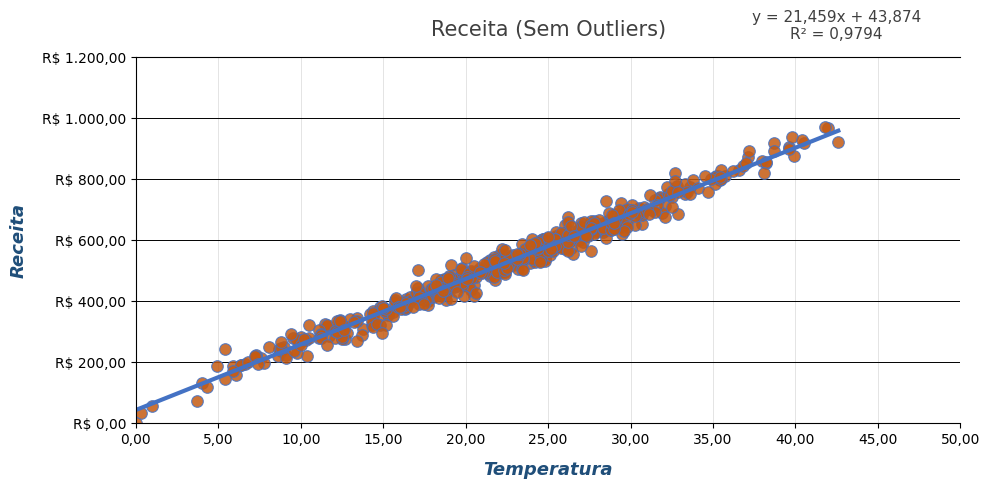

Nova Equação: y = 21.459x + 43.874
Novo R²: 0.9794 (97.94%)
MAE: R$ 19.70 | RMSE: R$ 25.08


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# 1. Carregar os dados
df = pd.read_excel('/Ice Cream.xlsx', sheet_name='in')

# 2. Regressão inicial para identificar os outliers (erros de base)
modelo_inicial = LinearRegression().fit(df[['Temperature']], df['Revenue'])
df['Previsto_Inicial'] = modelo_inicial.predict(df[['Temperature']])
df['Residuo'] = (df['Revenue'] - df['Previsto_Inicial']).abs()

# Filtrar removendo apenas os outliers extremos (desvio maior que R$ 150 da tendência)
# Dica: se quiser o filtro IQR completo (R² = 0,9812), troque o bloco abaixo pelo método IQR
outliers = df[df['Residuo'] > 150]
df_limpo = df[df['Residuo'] <= 150].copy()

print(f"Outliers removidos ({len(outliers)} registros):")
print(outliers[['Temperature', 'Revenue']])
print("-" * 50)

# 3. Nova Regressão Linear com a base limpa
X = df_limpo[['Temperature']]
y = df_limpo['Revenue']

modelo = LinearRegression()
modelo.fit(X, y)
y_pred = modelo.predict(X)

a = modelo.coef_[0]
b = modelo.intercept_
r2 = r2_score(y, y_pred)
mae = mean_absolute_error(y, y_pred)
rmse = np.sqrt(mean_squared_error(y, y_pred))

# 4. Montar o gráfico atualizado
fig, ax = plt.subplots(figsize=(10, 5))

ax.scatter(
    df_limpo['Temperature'], df_limpo['Revenue'],
    marker='s', s=90, color='#C55A11', edgecolors='#4472C4', linewidths=0.8,
    label='Receita (Dados Limpos)'
)

x_linha = np.linspace(df_limpo['Temperature'].min(), df_limpo['Temperature'].max(), 100)
y_linha = a * x_linha + b
ax.plot(x_linha, y_linha, linestyle=':', linewidth=2, color='#4472C4', label='Linha de Tendência')

ax.set_title('Receita (Sem Outliers)', fontsize=15, pad=15, color='#404040')
ax.set_xlabel('Temperatura', fontsize=13, fontweight='bold', fontstyle='italic', color='#1F4E79', labelpad=10)
ax.set_ylabel('Receita', fontsize=13, fontweight='bold', fontstyle='italic', color='#1F4E79', labelpad=10)

ax.set_xlim(0, 50)
ax.set_ylim(0, 1200)
ax.set_xticks(np.arange(0, 55, 5))
ax.set_yticks(np.arange(0, 1400, 200))

ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda val, pos: f'{val:,.2f}'.replace('.', ',')))
ax.yaxis.set_major_formatter(ticker.FuncFormatter(
    lambda val, pos: 'R$ ' + f'{val:,.2f}'.replace(',', 'X').replace('.', ',').replace('X', '.')
))

ax.yaxis.grid(True, color='black', linewidth=0.7)
ax.xaxis.grid(True, color='#D9D9D9', linewidth=0.5)
ax.set_axisbelow(True)
ax.spines['top'].set_color('black')
ax.spines['right'].set_visible(False)

eq_texto = f"y = {a:.3f}x + {b:.3f}\nR² = {r2:.4f}".replace('.', ',')
ax.text(
    0.85, 1.04, eq_texto,
    transform=ax.transAxes, fontsize=11, ha='center', va='bottom', color='#404040'
)

plt.tight_layout()
plt.show()

print(f"Nova Equação: y = {a:.3f}x + {b:.3f}")
print(f"Novo R²: {r2:.4f} ({r2*100:.2f}%)")
print(f"MAE: R$ {mae:.2f} | RMSE: R$ {rmse:.2f}")